In [8]:
import os, pandas as pd
os.chdir(r"C:\Users\emine\Desktop\rfm-xai-segmentation")

rfm = pd.read_csv("data/processed/rfm_segmented.csv")
rfm.head()


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [9]:
import os
os.makedirs("data/processed", exist_ok=True)
rfm.to_csv("data/processed/rfm_segmented.csv", index=False)
print("kaydedildi:", "data/processed/rfm_segmented.csv")


kaydedildi: data/processed/rfm_segmented.csv


In [10]:
import numpy as np
from sklearn.preprocessing import StandardScaler

X = rfm[["Recency", "Frequency", "Monetary"]].copy()
X_log = X.apply(np.log1p)           # log1p = log(x+1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)


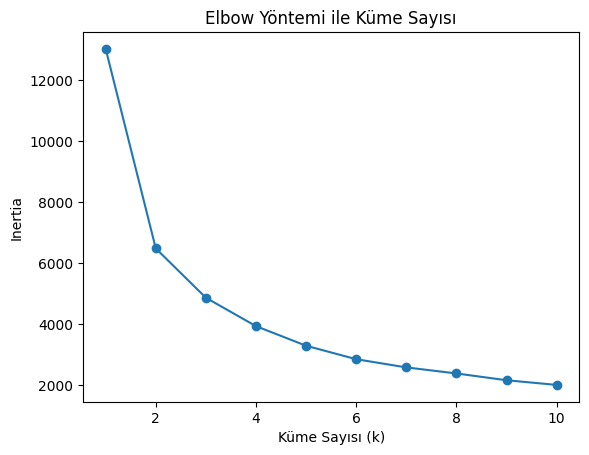

In [11]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
K = range(1, 11)
for k in K:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.plot(K, inertia, marker="o")
plt.xlabel("Küme Sayısı (k)")
plt.ylabel("Inertia")
plt.title("Elbow Yöntemi ile Küme Sayısı")
plt.show()


In [12]:
kmeans = KMeans(n_clusters=3, random_state=42)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(1)


,Recency,Frequency,Monetary
Cluster,,,
0,44.5,3.4,1257.7
1,17.1,13.3,7865.6
2,167.6,1.3,361.5


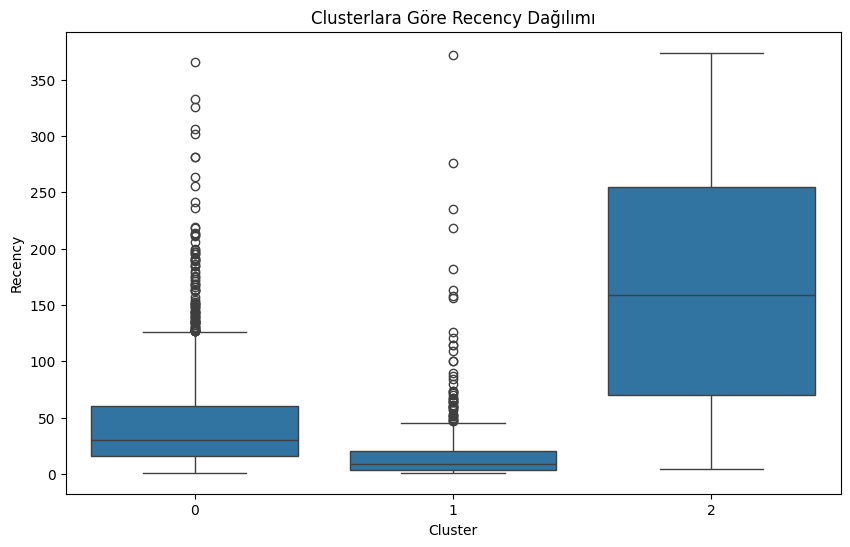

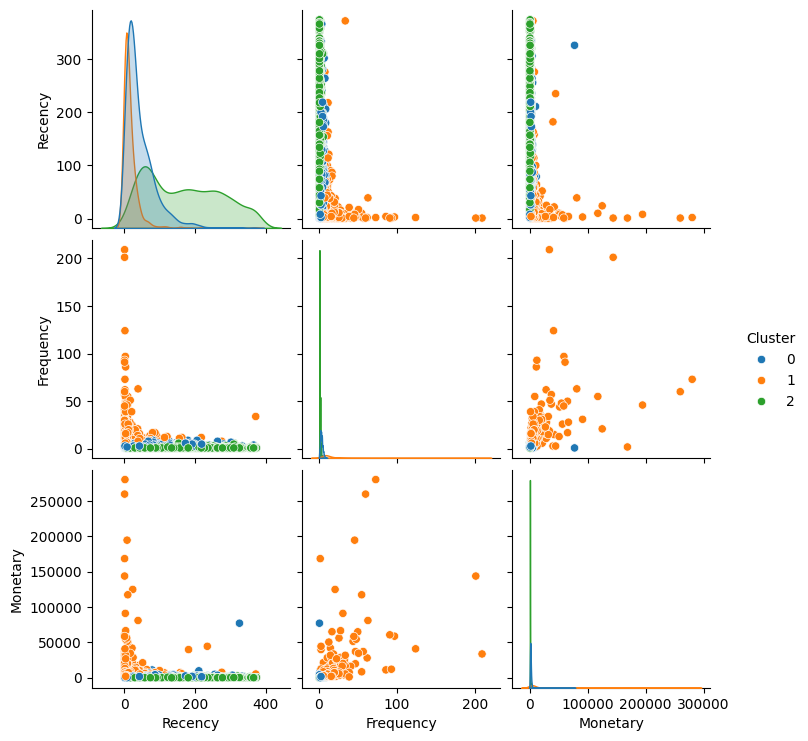

In [13]:
import seaborn as sns

plt.figure(figsize=(10,6))
sns.boxplot(x="Cluster", y="Recency", data=rfm)
plt.title("Clusterlara Göre Recency Dağılımı")
plt.show()

sns.pairplot(rfm, vars=["Recency","Frequency","Monetary"], hue="Cluster", palette="tab10")
plt.show()


In [14]:
rfm.to_csv("data/processed/rfm_clustered.csv", index=False)
print("rfm_clustered.csv kaydedildi.")


rfm_clustered.csv kaydedildi.


In [15]:
rfm["Segment"] = rfm["Cluster"].map({
    1: "VIP",
    0: "Regular",
    2: "Lost"
})

rfm.head()


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346.0,326,1,77183.60,0,Regular
1,12347.0,2,7,4310.00,1,VIP
2,12348.0,75,4,1797.24,0,Regular
3,12349.0,19,1,1757.55,0,Regular
4,12350.0,310,1,334.40,2,Lost
